Dataset:
     Outlook Temperature Humidity   Windy PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3      Rainy        Mild     High    Weak        Yes
4      Rainy        Cool   Normal    Weak        Yes
5      Rainy        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9      Rainy        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13     Rainy        Mild     High  Strong         No
Accuracy: 0.6666666666666666

Decision Tree Rules:
|--- Outlook_Overcast <= 0.50
|   |--- Humidity_High <= 0.50
|   |   |--- Windy_Weak <= 0.50
|   |   |   |--- class: 0
|   |   |--- Windy_Weak > 

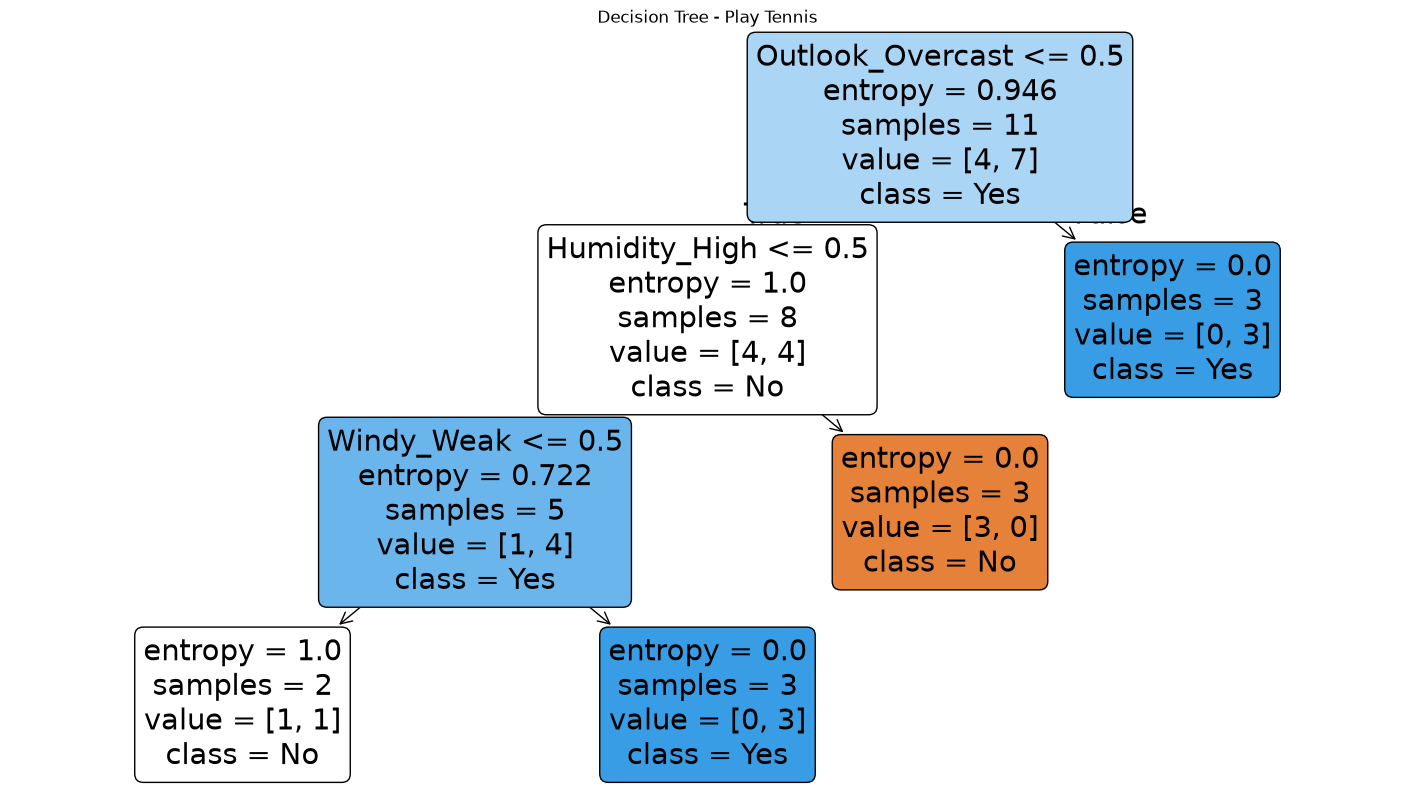

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn import metrics

# Load the dataset you already uploaded
df = pd.read_csv("tennis.csv")
print("Dataset:")
print(df)

# Features and target
feature_cols = ["Outlook", "Temperature", "Humidity", "Windy"]
X = df[feature_cols]
y = df["PlayTennis"]

# Convert categorical features into numeric columns
X_encoded = pd.get_dummies(X, columns=feature_cols)

# Encode target labels
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=1
)

# Build Decision Tree
clf = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=1
)

# Train the model
clf.fit(X_train, y_train)

# Predict test results
y_pred = clf.predict(X_test)

# Evaluate accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

# Display tree rules
print("\nDecision Tree Rules:")
print(export_text(clf, feature_names=list(X_encoded.columns)))

# Visualize the tree
plt.figure(figsize=(18, 10))
plot_tree(
    clf,
    feature_names=list(X_encoded.columns),
    class_names=[str(c) for c in target_encoder.classes_],
    filled=True,
    rounded=True
)
plt.title("Decision Tree - Play Tennis")
plt.show()
